# Cost-Based Splitting Criteria: Employee Attrition (IBM HR Data)

An ordinary CART tree treats every mistake as equally bad. In business that is rarely true:

| | Predicted: Stays | Predicted: Leaves |
|---|---|---|
| **Actually stays** | Correct (cost 0) | **False alarm**: an unnecessary retention talk (cost **1**) |
| **Actually leaves** | **Missed leaver**: we lose the employee and must hire and train a replacement (cost **5**) | Correct (cost 0) |

A **cost-based splitting criterion** builds the tree so that the **total cost of mistakes** is as low as possible, instead of making the groups as "pure" as possible (which is what Gini does).

In this notebook we compare three trees:

1. **Ordinary CART**: Gini, ignores costs
2. **Cost-based tree**: splits chosen to reduce total cost directly
3. **Cost-weighted CART**: Gini, but each leaver counts 5 times (the scikit-learn way)

The data file sits in `../data/` (IBM HR Analytics sample data), so the notebook runs as-is from the `notebooks/` folder.

## Step 0: Install the cost-sensitive library (run once)

Or simply run `pip install -r requirements.txt` from the repo root.

In [1]:
%pip install empulse -q

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


## Step 1: Import the libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from empulse.models import CSTreeClassifier

## Step 2: Load and prepare the data

In [3]:
# Load the data and drop columns that carry no information
df = pd.read_csv("../data/HR-Employee-Attrition.csv")
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])
# y = target (1 = left, 0 = stayed); X = inputs, with text columns turned into 0/1
y = (df["Attrition"] == "Yes").astype(int)
X = pd.get_dummies(df.drop(columns="Attrition"), drop_first=True).astype(int)
# 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1029, 44)  Test: (441, 44)


## Step 3: Set the costs

These are the two numbers from the cost matrix above. You can change them and re-run the notebook.

In [4]:
FP_COST = 1   # false alarm: predicted Leaves, but the employee stays
FN_COST = 5   # missed leaver: predicted Stays, but the employee leaves

## Step 4: How a group (node) chooses its label

Every group of employees in the tree must be labelled either "Stays" or "Leaves".

- If we label the group **Stays**, every leaver in it is a missed leaver: cost = leavers × 5
- If we label the group **Leaves**, every stayer in it is a false alarm: cost = stayers × 1

The group takes whichever label is **cheaper**.

In [5]:
def node_cost(target):
    cost_if_stays = target.sum() * FN_COST                    # every leaver is missed
    cost_if_leaves = (len(target) - target.sum()) * FP_COST   # every stayer is a false alarm
    return min(cost_if_stays, cost_if_leaves)                 # the group takes the cheaper label

print("Label everyone 'Stays' :", y_train.sum() * FN_COST)
print("Label everyone 'Leaves':", (len(y_train) - y_train.sum()) * FP_COST)
print("Cheaper choice         :", node_cost(y_train))

Label everyone 'Stays' : 830
Label everyone 'Leaves': 863
Cheaper choice         : 830


With these costs, a group is labelled **Leaves** as soon as more than **1 in 6** of its employees leave (because 1 ÷ (1 + 5) = 0.167). Ordinary CART only does this when more than **half** leave.

## Step 5: Gini vs cost: which first split would each choose?

For a few candidate questions we calculate:

- **Gini drop**: how much purer the two groups become (what ordinary CART maximises)
- **Cost drop**: how much the total cost of mistakes falls (what the cost-based tree maximises)

In [6]:
def gini(target):
    p = target.mean()          # share of leavers in the group
    return 2 * p * (1 - p)

questions = {
    "OverTime = Yes":         X_train["OverTime_Yes"] == 1,
    "YearsAtCompany <= 2":    X_train["YearsAtCompany"] <= 2,
    "TotalWorkingYears <= 2": X_train["TotalWorkingYears"] <= 2,
    "JobLevel = 1":           X_train["JobLevel"] == 1,
    "MonthlyIncome <= 3000":  X_train["MonthlyIncome"] <= 3000,
}

rows = []
for question, mask in questions.items():
    yes, no = y_train[mask], y_train[~mask]      # the two groups after the split
    w = len(yes) / len(y_train)                  # share of employees in the "yes" group
    rows.append({"Question": question,
                 "Group size": len(yes),
                 "Leaver rate": round(yes.mean(), 2),
                 "Gini drop": round(gini(y_train) - (w * gini(yes) + (1 - w) * gini(no)), 4),
                 "Cost drop": node_cost(y_train) - node_cost(yes) - node_cost(no)})

splits = pd.DataFrame(rows)
splits

,Question,Group size,Leaver rate,Gini drop,Cost drop
0,OverTime = Yes,302,0.28,0.0127,214
1,YearsAtCompany <= 2,238,0.33,0.0167,230
2,TotalWorkingYears <= 2,81,0.53,0.0233,177
3,JobLevel = 1,362,0.27,0.0117,214
4,MonthlyIncome <= 3000,260,0.30,0.0130,208


In [7]:
print("Gini would choose:", splits.loc[splits["Gini drop"].idxmax(), "Question"])
print("Cost would choose:", splits.loc[splits["Cost drop"].idxmax(), "Question"])

Gini would choose: TotalWorkingYears <= 2
Cost would choose: YearsAtCompany <= 2


## Step 6: Model 1: ordinary CART (Gini)

All three trees use the same size settings (`max_depth=3`, at least 20 employees per leaf) so the comparison is fair.

In [8]:
gini_tree = DecisionTreeClassifier(criterion="gini", max_depth=3, min_samples_leaf=20, random_state=42)
gini_tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

## Step 7: Model 2: cost-based tree

`CSTreeClassifier` from the `empulse` library uses `criterion="cost"`: at every node it picks the split that reduces the total cost of mistakes the most.

In [9]:
cost_tree = CSTreeClassifier(criterion="cost", fp_cost=FP_COST, fn_cost=FN_COST,
                             max_depth=3, min_samples_leaf=20, random_state=42)
cost_tree.fit(X_train, y_train)

,fn_cost,5
,fp_cost,1
,max_depth,3
,min_samples_leaf,20
,random_state,42
,tp_cost,0.0
,tn_cost,0.0
,loss,None
,criterion,'cost'
,splitter,'best'
,min_samples_split,2


### The rules of the cost-based tree

scikit-learn's `plot_tree` does not accept this model, so this small function prints the tree as IF–THEN rules.

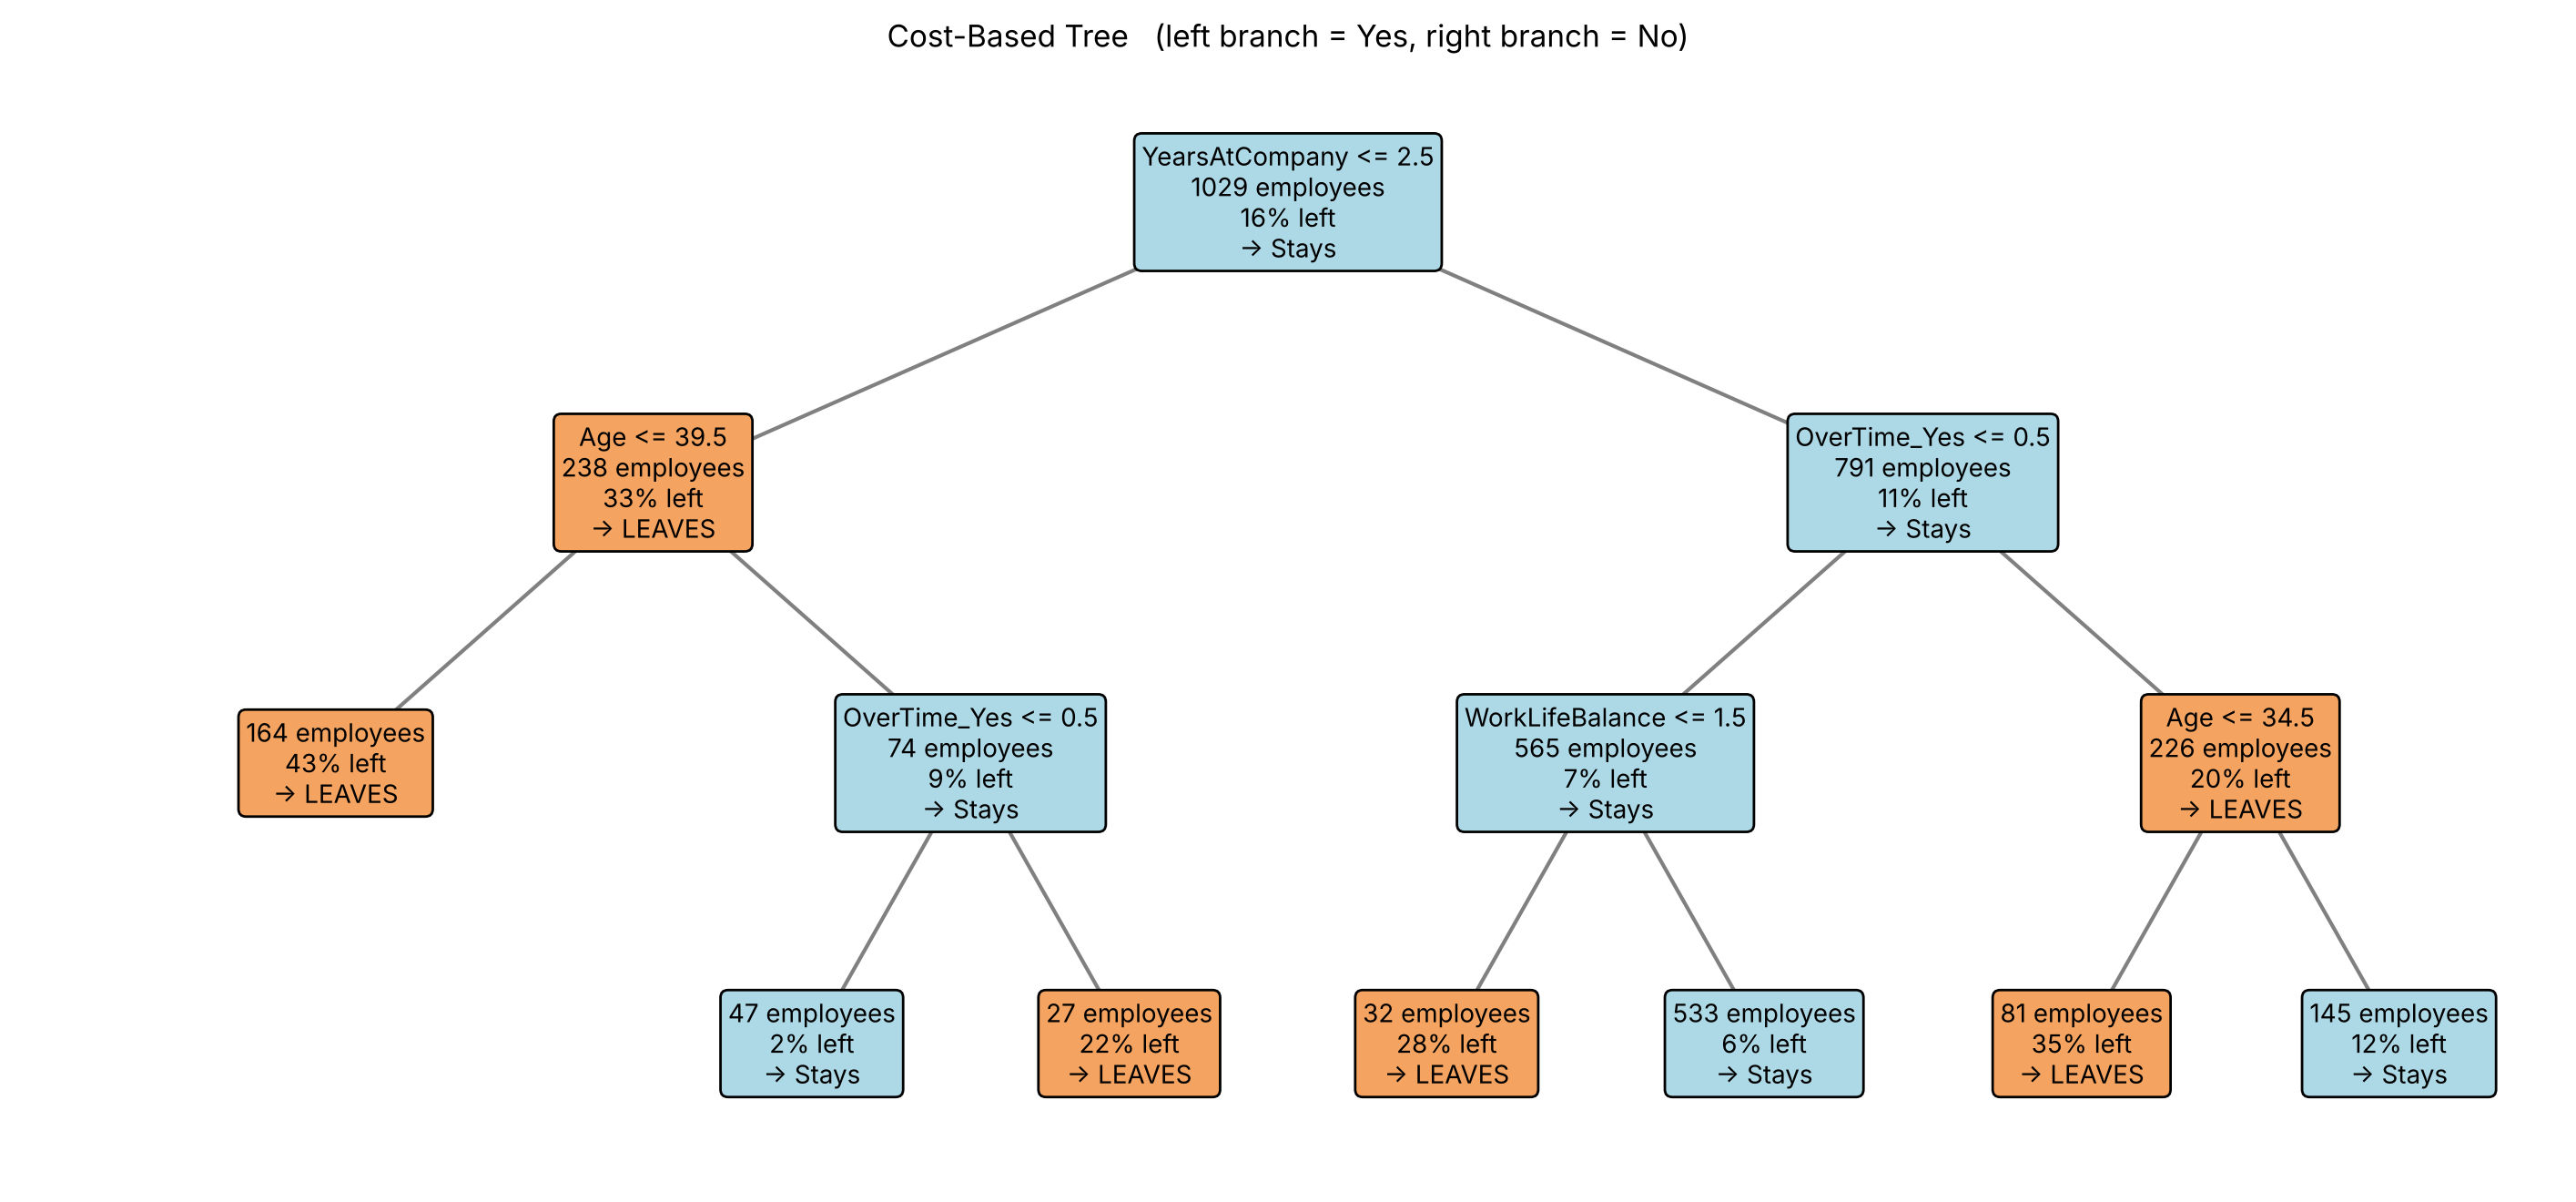

In [10]:
def plot_cost_tree(model, names):
    t = model.tree_
    plt.figure(figsize=(18, 8))
    plt.axis("off")
    def draw(node, x, y, gap):
        p = t.value[node][0][1]                                    # share of leavers in this group
        label = "LEAVES" if p * FN_COST > (1 - p) * FP_COST else "Stays"
        text = f"{t.n_node_samples[node]} employees\n{p:.0%} left\n→ {label}"
        if t.children_left[node] != -1:                            # not a leaf: add the question and draw two branches
            text = f"{names[t.feature[node]]} <= {t.threshold[node]:.1f}\n" + text
            for child, dx in [(t.children_left[node], -gap), (t.children_right[node], gap)]:
                plt.plot([x, x + dx], [y, y - 1], color="grey")
                draw(child, x + dx, y - 1, gap / 2)
        colour = "sandybrown" if label == "LEAVES" else "lightblue"
        plt.text(x, y, text, ha="center", va="center", bbox=dict(boxstyle="round", fc=colour))

    draw(0, 0, 0, 4)
    plt.xlim(-8, 8)
    plt.ylim(-3.5, 0.5)
    plt.title("Cost-Based Tree   (left branch = Yes, right branch = No)")
    plt.show()

plot_cost_tree(cost_tree, list(X.columns))

## Step 8: Model 3: cost-weighted CART (the scikit-learn way)

scikit-learn has no cost criterion, but `class_weight` lets each leaver count 5 times when Gini is calculated. The splits are still chosen by Gini, but on cost-weighted data.

In [11]:
weighted_tree = DecisionTreeClassifier(criterion="gini", max_depth=3, min_samples_leaf=20,
                                       class_weight={0: FP_COST, 1: FN_COST}, random_state=42)
weighted_tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: 1, 1: 5}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max

## Step 9: Compare the three trees on the test data

In [12]:
def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp * FP_COST + fn * FN_COST

models = {"Ordinary CART (Gini)": gini_tree,
          "Cost-based tree": cost_tree,
          "Cost-weighted CART": weighted_tree}
# Predictions of each tree, plus a baseline that says "Stays" (0) for everyone
preds = {name: model.predict(X_test) for name, model in models.items()}
preds["No model (everyone Stays)"] = y_test * 0

rows = []
for name, pred in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Model": name,
                 "Accuracy": round((pred == y_test).mean(), 3),
                 "Leavers caught": tp,
                 "Leavers missed": fn,
                 "False alarms": fp,
                 "Total cost": total_cost(y_test, pred)})

results = pd.DataFrame(rows)
results

,Model,Accuracy,Leavers caught,Leavers missed,False alarms,Total cost
0,Ordinary CART (Gini),0.830,17,54,21,291
1,Cost-based tree,0.707,38,33,96,261
2,Cost-weighted CART,0.737,43,28,88,228
3,No model (everyone Stays),0.839,0,71,0,355


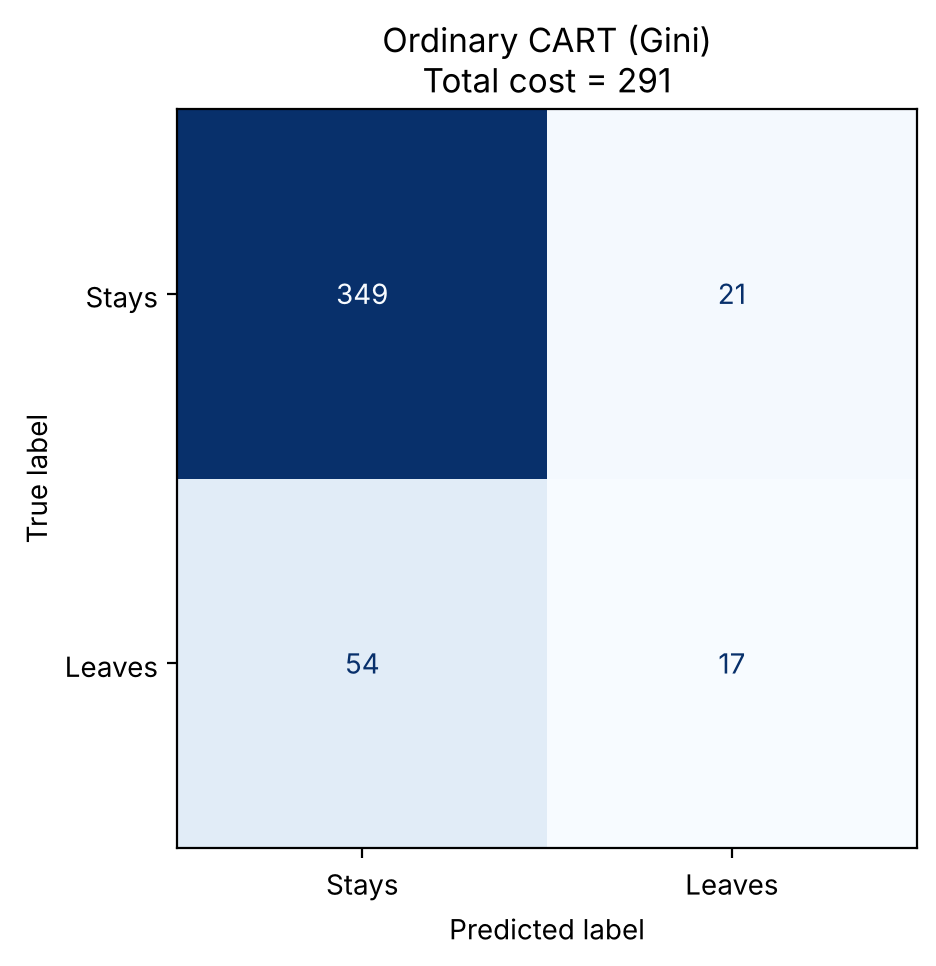

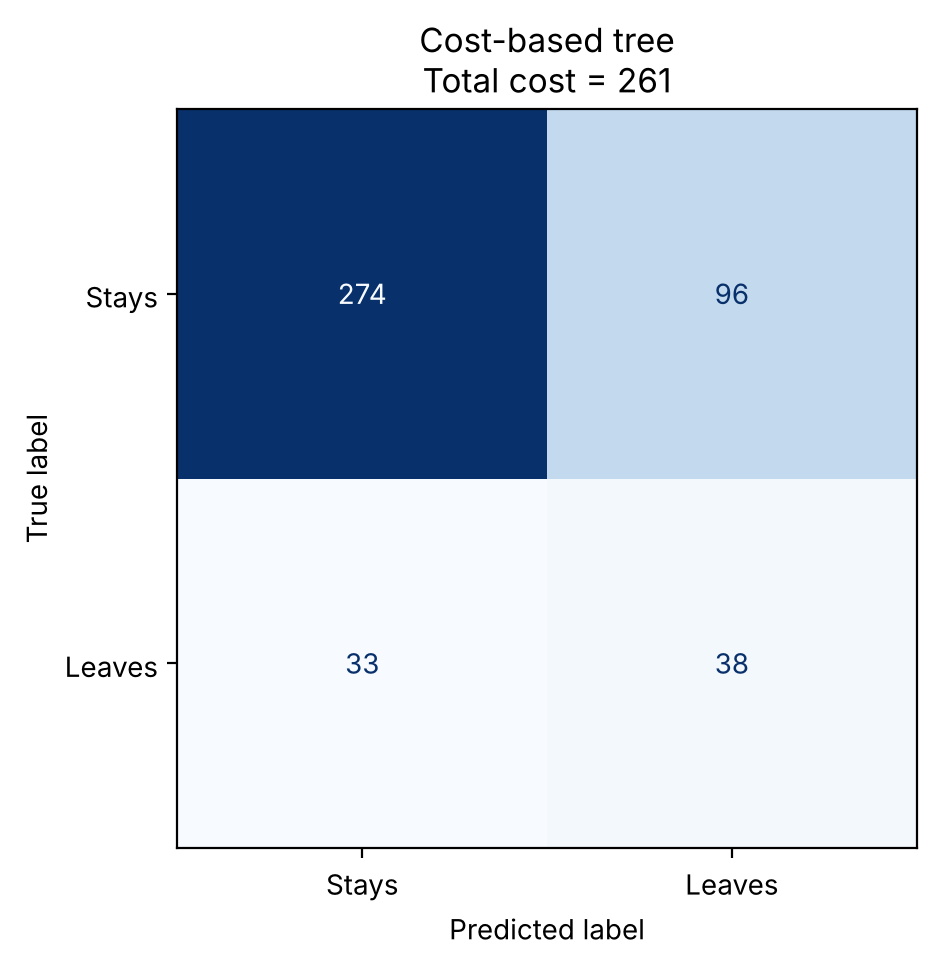

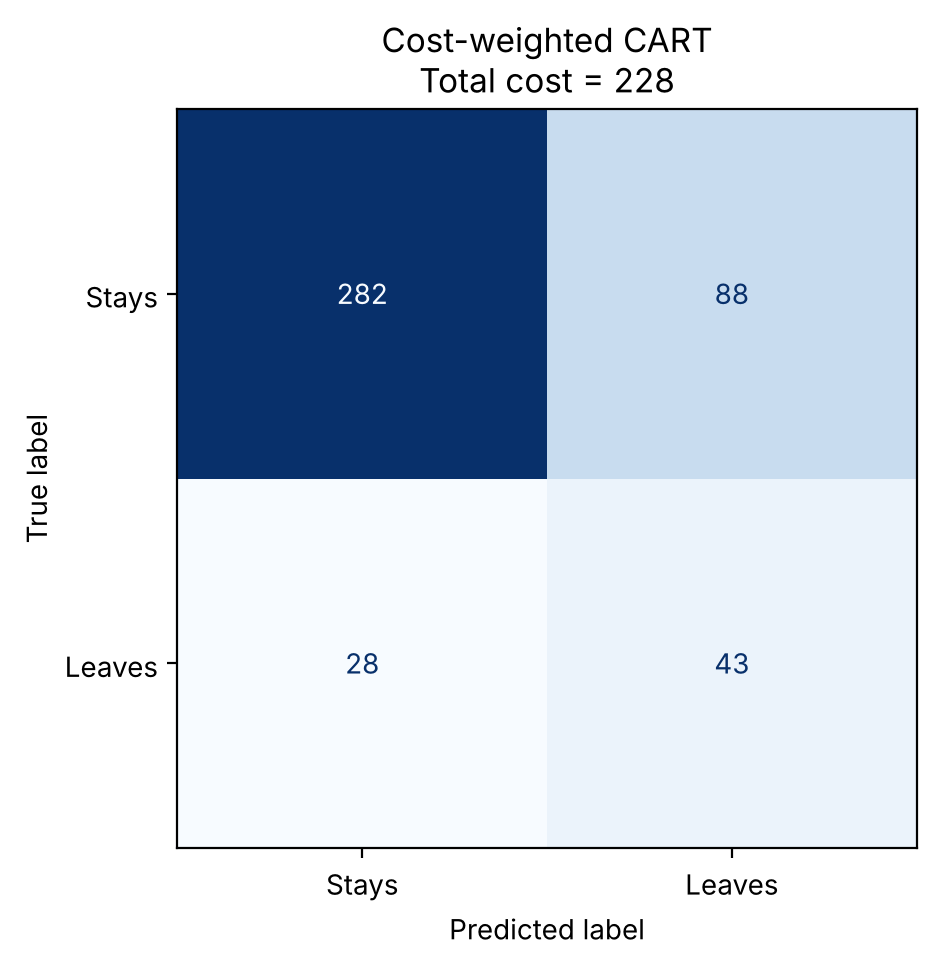

In [13]:
for name, model in models.items():
    pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stays", "Leaves"],
                                            cmap="Blues", colorbar=False)
    plt.title(f"{name}\nTotal cost = {total_cost(y_test, pred)}")
    plt.show()

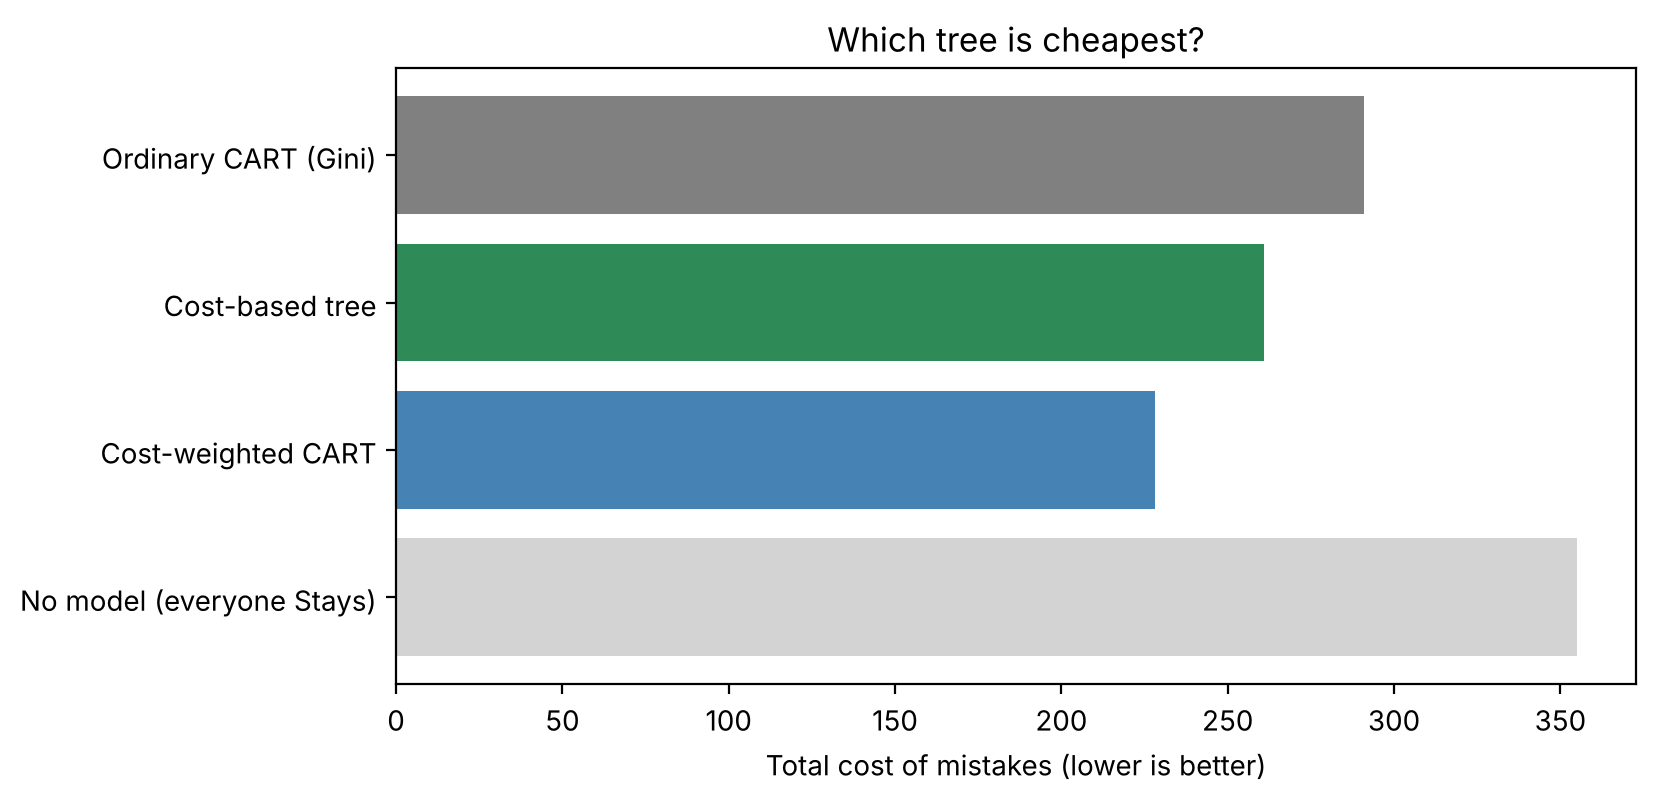

In [14]:
plt.figure(figsize=(8, 4))
plt.barh(results["Model"], results["Total cost"], color=["grey", "seagreen", "steelblue", "lightgrey"])
plt.xlabel("Total cost of mistakes (lower is better)")
plt.title("Which tree is cheapest?")
plt.gca().invert_yaxis()
plt.show()

## Step 10: What if a missed leaver costs more (or less)?

We rebuild the cost-based tree for different values of `FN_COST` and count how many employees it flags as likely to leave.

 Cost of a missed leaver  Employees flagged  Leavers caught  Leavers missed
                       1                 23               7              64
                       2                 23               7              64
                       3                 62              21              50
                       5                134              38              33
                       8                202              49              22
                      10                341              64               7


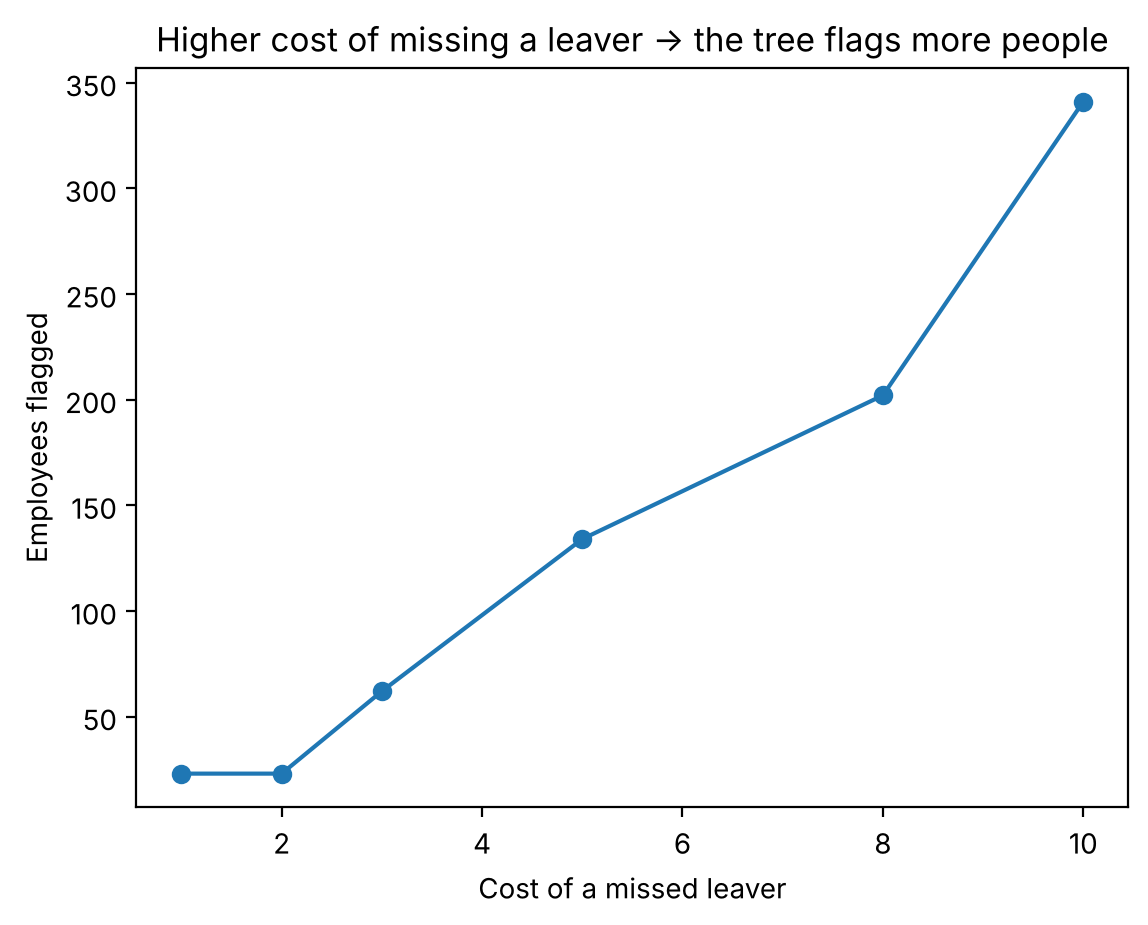

In [15]:
rows = []
for cost in [1, 2, 3, 5, 8, 10]:
    tree = CSTreeClassifier(criterion="cost", fp_cost=1, fn_cost=cost,
                            max_depth=3, min_samples_leaf=20, random_state=42)
    pred = tree.fit(X_train, y_train).predict(X_test)
    caught = ((pred == 1) & (y_test == 1)).sum()
    rows.append({"Cost of a missed leaver": cost,
                 "Employees flagged": pred.sum(),
                 "Leavers caught": caught,
                 "Leavers missed": y_test.sum() - caught})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False))

sens.plot(x="Cost of a missed leaver", y="Employees flagged", marker="o", legend=False,
          ylabel="Employees flagged", title="Higher cost of missing a leaver → the tree flags more people")
plt.show()

## Interpretation

**Step 5: the first split**

- Gini prefers **TotalWorkingYears ≤ 2**: a small group of 81 employees in which 53% leave. It is very "pure", but it covers only a few people.
- The cost criterion prefers **YearsAtCompany ≤ 2**: a larger group of 238 employees with a 33% leaver rate. Since a missed leaver costs 5 times a false alarm, flagging this whole group catches many more leavers for an acceptable number of false alarms.
- The cost-based tree in Step 7 does start with *YearsAtCompany ≤ 2.5*, the same idea.

**Step 7: who the cost-based tree flags as likely to leave**

- Employees with 2 years or less at the company, aged 39 or younger (43% left)
- Newer employees over 39 who work overtime (22% left)
- Longer-serving employees with no overtime but the lowest work-life balance rating (28% left)
- Longer-serving employees aged 34 or younger who work overtime (35% left)

In none of these groups do most employees leave. The tree still labels them "Leaves" because above 1 in 6, acting is cheaper than doing nothing.

**Step 9: comparing the trees**

- **Ordinary CART** has 83% accuracy but catches only **17 of 71** leavers. Total cost = **291**.
- **Cost-based tree**: accuracy falls to 71%, but it catches **38** leavers. Total cost = **261**, about 10% lower.
- **Cost-weighted CART** catches **43** leavers. Total cost = **228**, the cheapest of the three and about 22% below ordinary CART.
- **Doing nothing** (everyone "Stays") has the *highest* accuracy (84%) but the *highest* cost (355). When mistakes have different costs, accuracy is the wrong yardstick.

Why does the weighted Gini tree beat the pure cost criterion here? The cost criterion only rewards a split if it changes a group's label, so it can pass over splits that would set up better splits further down. Gini changes smoothly and avoids this; Breiman et al. preferred Gini over misclassification-based criteria for the same reason. On other data or settings the order can change, so always compare both.

**Step 10: changing the cost**

- When a missed leaver costs the same as a false alarm (or twice as much), the tree flags only 23 employees.
- At a cost of 5 it flags 134; at 10 it flags 341 (77% of the test employees) and catches 64 of the 71 leavers.

**Business message:** the cost matrix is a management decision, not a statistical one. Before using the model, HR must estimate the real cost of replacing an employee and the cost of a retention action.

---
## Summary

| | Ordinary CART | Cost-based tree | Cost-weighted CART |
|---|---|---|---|
| Splitting rule | Gini (purity) | Total cost of mistakes | Gini on cost-weighted data |
| Leaf label | Majority class (> 50%) | Cheaper label (> 1 in 6 here) | Weighted majority |
| Uses the cost matrix? | No | Yes | Yes, as weights |
| Library | scikit-learn | empulse | scikit-learn |

**Key takeaways**

1. A cost-based criterion changes two things: **which split** is chosen and **where the label threshold** sits (1 in 6 here, instead of 1 in 2).
2. When mistakes have unequal costs, judge models by **total cost**, not accuracy.
3. In scikit-learn the easy route is `class_weight`. For a true cost criterion use `CSTreeClassifier(criterion="cost")` from `empulse`.
4. The results depend on the cost numbers, so get them from the business.